# 07 — Statistical Hypothesis Tests (complete and justified)

## Objective
Grading criterion **1.2** asks for at least two statistical tests, **each explicitly justified**. Notebook 01 ran a Kruskal–Wallis test and a χ² test. This notebook completes the analysis so that every test choice is *demonstrated* rather than asserted:

| # | Test | Question | Why this test |
|---|---|---|---|
| 1 | D'Agostino–Pearson K² and Shapiro–Wilk; Brown–Forsythe (Levene, median-centred) | Are the numeric features normal and homoscedastic within each action? | These are the assumptions of one-way ANOVA. If they fail, a rank-based test is required. |
| 2 | Kruskal–Wallis H + ε², with Benjamini–Hochberg correction over the 7 numeric features | Does each numeric feature differ between the four actions? | Non-parametric alternative to ANOVA for k = 4 independent groups; BH controls the false discovery rate because 7 tests are run. |
| 3 | Dunn post-hoc test (Holm correction) + Cliff's δ | *Which* pairs of actions differ — in particular `deny` vs `reset-both`? | Kruskal–Wallis is an omnibus test: it only says that *at least one* group differs. Dunn's test uses the same joint ranks; Cliff's δ measures the size of each difference. |
| 4 | χ² test of independence + Cramér's V | Are NAT source-port status and destination port associated with the action? | Two categorical variables; valid when expected counts are ≥ 5 (checked). |
| 5 | Spearman rank correlation with p-values (BH-corrected) | Which numeric features are monotonically related? | Data are skewed and not normal, so a rank correlation is used instead of Pearson. |

**Main analysis on deduplicated data** (57,170 unique flows): the 8,362 exact duplicates would violate the independence assumption shared by all these tests. Results on the original data are reported as a sensitivity check.

**Large-sample warning.** With n ≈ 57,000, almost any difference is "significant". The conclusions therefore rely on **effect sizes** (ε², Cliff's δ, Cramér's V, ρ), not on p-values alone.

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "statistical_tests.py").exists():
    raise FileNotFoundError("Run this notebook from the repository root or from notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

from src.statistical_tests import deduplicate, kruskal_bytes_by_action, chi_square_nat_source_port, format_p_value

RANDOM_STATE = 42
ACTIONS = ["allow", "deny", "drop", "reset-both"]
NUMERIC = ["Bytes", "Bytes Sent", "Bytes Received", "Packets", "Elapsed Time (sec)", "pkts_sent", "pkts_received"]
FIG = ROOT / "docs" / "latex" / "figures" / "ch03"; FIG.mkdir(parents=True, exist_ok=True)
REP = ROOT / "reports"

raw = pd.read_csv(ROOT / "data" / "raw" / "log2.csv")
raw["Action"] = raw["Action"].str.strip().str.lower()
df = deduplicate(raw)
print(f"original: {len(raw):,} rows | deduplicated: {len(df):,} rows")
display(df["Action"].value_counts().reindex(ACTIONS).to_frame("unique flows"))

def bh(p):
    # Benjamini–Hochberg adjusted p-values
    p = np.asarray(p, float); n = len(p); order = np.argsort(p)
    adj = np.empty(n); adj[order] = np.minimum.accumulate((p[order] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.minimum(adj, 1)

def holm(p):
    p = np.asarray(p, float); n = len(p); order = np.argsort(p)
    adj = np.empty(n); adj[order] = np.maximum.accumulate(p[order] * (n - np.arange(n)))
    return np.minimum(adj, 1)

fmt = lambda p: format_p_value(p) if p < 1e-4 else f"{p:.4f}"
summary = []          # one line per test, exported at the end

original: 65,532 rows | deduplicated: 57,170 rows


,unique flows
Action,
allow,37439
deny,8042
drop,11635
reset-both,54


## Test 1 — Are the ANOVA assumptions met?

- **H0 (normality):** within each action, the feature follows a normal distribution. Tested with D'Agostino–Pearson K² on all rows and Shapiro–Wilk on a random sample of at most 5,000 rows per group (Shapiro–Wilk is only reliable up to n ≈ 5,000).
- **H0 (equal variances):** the variance is the same in the four actions. Brown–Forsythe test (Levene centred on the median), which is robust to non-normality.

Tested on `log1p(Bytes)`, i.e. *after* the transformation used in the pipeline: if even the log-transformed data are not normal, the raw data are certainly not.

,n,skewness,K2,p (K2),Shapiro W,p (Shapiro)
action,,,,,,
allow,37439,1.26,7662.4,< 1e-300 (numerical underflow),0.8800,2.4784e-52
deny,8042,2.68,4691.2,< 1e-300 (numerical underflow),0.5901,6.5054e-76
drop,11635,-0.58,53233.2,< 1e-300 (numerical underflow),0.6102,7.4019e-75
reset-both,54,-0.17,5.2,0.0736,0.8284,2.0771e-06


Brown–Forsythe on log1p(Bytes): W = 6216.6, p = < 1e-300 (numerical underflow)


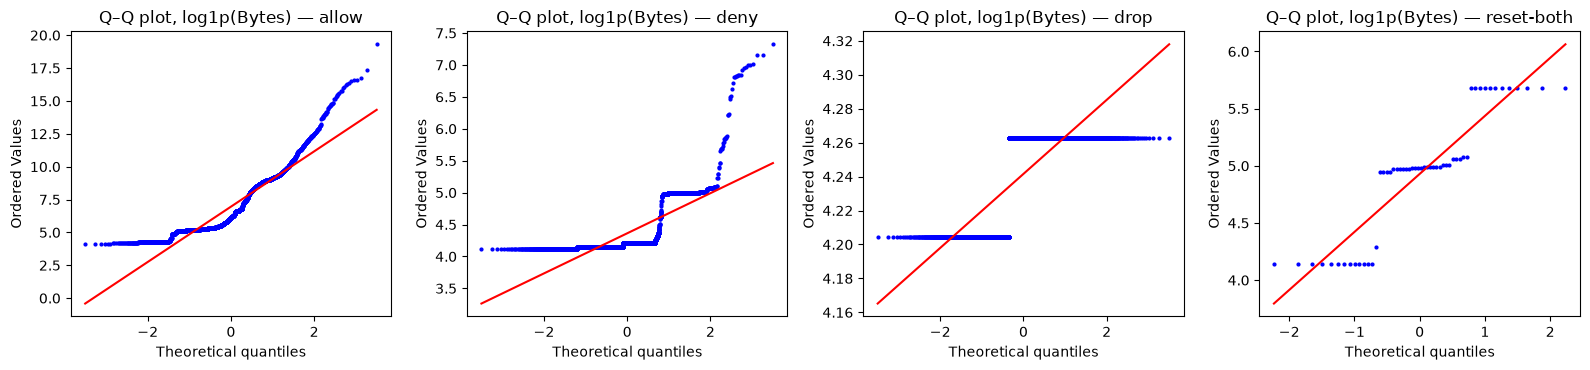

In [2]:
rows = []
for a in ACTIONS:
    x = np.log1p(df.loc[df["Action"] == a, "Bytes"].to_numpy())
    k2, p_k2 = stats.normaltest(x) if len(x) >= 20 else (np.nan, np.nan)
    s = pd.Series(x).sample(min(len(x), 5000), random_state=RANDOM_STATE)
    w, p_w = stats.shapiro(s)
    rows.append({"action": a, "n": len(x), "skewness": stats.skew(x), "K2": k2, "p (K2)": p_k2,
                 "Shapiro W": w, "p (Shapiro)": p_w})
normality = pd.DataFrame(rows).set_index("action")
display(normality.style.format({"skewness": "{:.2f}", "K2": "{:.1f}", "Shapiro W": "{:.4f}",
                                "p (K2)": fmt, "p (Shapiro)": fmt}))

bf, p_bf = stats.levene(*[np.log1p(df.loc[df["Action"] == a, "Bytes"]) for a in ACTIONS], center="median")
print(f"Brown–Forsythe on log1p(Bytes): W = {bf:.1f}, p = {fmt(p_bf)}")
summary.append({"test": "Shapiro–Wilk on log1p(Bytes), each action", "statistic": "see table",
                "p_value": normality["p (Shapiro)"].max(),
                "effect_size": "-", "conclusion": "normality rejected in all four groups"})
summary.append({"test": "Brown–Forsythe (Levene, median)", "statistic": round(bf, 1), "p_value": p_bf,
                "effect_size": "-", "conclusion": "variances differ between actions"})

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, a in zip(axes, ACTIONS):
    x = np.log1p(df.loc[df["Action"] == a, "Bytes"])
    stats.probplot(pd.Series(x).sample(min(len(x), 3000), random_state=RANDOM_STATE), dist="norm", plot=ax)
    ax.set_title(f"Q–Q plot, log1p(Bytes) — {a}"); ax.get_lines()[0].set_markersize(2)
plt.tight_layout(); fig.savefig(FIG / "qq_plots_log_bytes.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusion of test 1.** Shapiro–Wilk rejects normality in all four groups (the K² test does not reject it for `reset-both`, where n = 54 gives it little power, but Shapiro–Wilk does), the Q–Q plots bend away from the line, and the variances are not equal. One-way ANOVA is therefore not appropriate: the rank-based **Kruskal–Wallis** test is used in test 2.

## Test 2 — Kruskal–Wallis on every numeric feature

- **H0:** the four actions come from the same distribution (equal mean ranks). **H1:** at least one action differs.
- Effect size ε² = H / (n − 1) (same definition as `src/statistical_tests.py`): ≈ 0.01 small, ≈ 0.08 medium, ≥ 0.26 large.
- Seven features are tested, so the p-values are adjusted with **Benjamini–Hochberg**.

In [3]:
def kw(data, col):
    H, p = stats.kruskal(*[data.loc[data["Action"] == a, col] for a in ACTIONS])
    return H, p, H / (len(data) - 1)

kw_rows = []
for col in NUMERIC:
    H, p, e = kw(df, col); H0, p0, e0 = kw(raw, col)
    kw_rows.append({"feature": col, "H (unique)": H, "p (unique)": p, "epsilon² (unique)": e,
                    "H (original)": H0, "epsilon² (original)": e0})
kw_df = pd.DataFrame(kw_rows)
kw_df["p BH-adjusted"] = bh(kw_df["p (unique)"])
kw_df = kw_df.sort_values("epsilon² (unique)", ascending=False).set_index("feature")
display(kw_df.style.format({"H (unique)": "{:,.0f}", "H (original)": "{:,.0f}", "epsilon² (unique)": "{:.3f}",
                            "epsilon² (original)": "{:.3f}", "p (unique)": fmt, "p BH-adjusted": fmt}))
kw_df.to_csv(REP / "kruskal_wallis_all_features.csv")

check = kruskal_bytes_by_action(df)   # same result as the project helper
assert np.isclose(check["H"], kw_df.loc["Bytes", "H (unique)"])
for col in ["Bytes", "Elapsed Time (sec)"]:
    summary.append({"test": f"Kruskal–Wallis, {col} by action", "statistic": round(kw_df.loc[col, "H (unique)"], 0),
                    "p_value": kw_df.loc[col, "p BH-adjusted"],
                    "effect_size": f"ε² = {kw_df.loc[col, 'epsilon² (unique)']:.3f}", "conclusion": "distributions differ"})

,H (unique),p (unique),epsilon² (unique),H (original),epsilon² (original),p BH-adjusted
feature,,,,,,
Elapsed Time (sec),"40,093",< 1e-300 (numerical underflow),0.701,"51,428",0.785,< 1e-300 (numerical underflow)
Packets,"37,713",< 1e-300 (numerical underflow),0.660,"48,398",0.739,< 1e-300 (numerical underflow)
Bytes,"34,771",< 1e-300 (numerical underflow),0.608,"44,288",0.676,< 1e-300 (numerical underflow)
pkts_received,"34,694",< 1e-300 (numerical underflow),0.607,"44,703",0.682,< 1e-300 (numerical underflow)
Bytes Received,"33,879",< 1e-300 (numerical underflow),0.593,"43,965",0.671,< 1e-300 (numerical underflow)
Bytes Sent,"28,533",< 1e-300 (numerical underflow),0.499,"37,074",0.566,< 1e-300 (numerical underflow)
pkts_sent,"15,323",< 1e-300 (numerical underflow),0.268,"20,655",0.315,< 1e-300 (numerical underflow)


## Test 3 — Dunn post-hoc test: which actions differ?

For each pair of actions, Dunn's z-statistic compares the mean ranks from the Kruskal–Wallis ranking (with tie correction); p-values are adjusted with **Holm** over the 6 pairs. **Cliff's δ** (from the Mann–Whitney U statistic) gives the size and direction of each difference: |δ| < 0.147 negligible, < 0.33 small, < 0.474 medium, otherwise large.

In [4]:
def dunn(data, col):
    x = data[col].to_numpy(); g = data["Action"].to_numpy(); n = len(x)
    r = stats.rankdata(x)
    _, counts = np.unique(x, return_counts=True)
    tie = (counts ** 3 - counts).sum() / (12 * (n - 1))
    out = []
    for i, a in enumerate(ACTIONS):
        for b in ACTIONS[i + 1:]:
            ra, rb = r[g == a], r[g == b]
            se = np.sqrt((n * (n + 1) / 12 - tie) * (1 / len(ra) + 1 / len(rb)))
            z = (ra.mean() - rb.mean()) / se
            U = stats.mannwhitneyu(x[g == a], x[g == b]).statistic
            out.append({"feature": col, "pair": f"{a} vs {b}", "z": z, "p": 2 * stats.norm.sf(abs(z)),
                        "cliffs_delta": 2 * U / (len(ra) * len(rb)) - 1})
    res = pd.DataFrame(out); res["p Holm"] = holm(res["p"])
    res["magnitude"] = pd.cut(res["cliffs_delta"].abs(), [-1, 0.147, 0.33, 0.474, 1.01],
                              labels=["negligible", "small", "medium", "large"])
    return res

dunn_df = pd.concat([dunn(df, c) for c in ["Bytes", "Packets", "Elapsed Time (sec)"]], ignore_index=True)
display(dunn_df.style.format({"z": "{:.2f}", "p": fmt, "p Holm": fmt, "cliffs_delta": "{:+.3f}"}))
dunn_df.to_csv(REP / "dunn_posthoc.csv", index=False)

drb = dunn_df[dunn_df["pair"] == "deny vs reset-both"].set_index("feature")
display(drb[["z", "p Holm", "cliffs_delta", "magnitude"]])
summary.append({"test": "Dunn post-hoc (Holm), deny vs reset-both, Bytes", "statistic": round(drb.loc["Bytes", "z"], 2),
                "p_value": drb.loc["Bytes", "p Holm"], "effect_size": f"δ = {drb.loc['Bytes', 'cliffs_delta']:+.3f}",
                "conclusion": "see interpretation"})

,feature,pair,z,p,cliffs_delta,p Holm,magnitude
0,Bytes,allow vs deny,143.48,< 1e-300 (numerical underflow),+0.934,< 1e-300 (numerical underflow),large
1,Bytes,allow vs drop,145.90,< 1e-300 (numerical underflow),+0.946,< 1e-300 (numerical underflow),large
2,Bytes,allow vs reset-both,7.79,6.9639e-15,+0.705,2.0892e-14,large
3,Bytes,deny vs drop,-14.81,1.1921e-49,-0.382,4.7685e-49,medium
4,Bytes,deny vs reset-both,-5.15,2.5993e-07,-0.504,5.1986e-07,large
5,Bytes,drop vs reset-both,-3.58,0.0003,-0.519,0.0003,large
6,Packets,allow vs deny,138.96,< 1e-300 (numerical underflow),+0.946,< 1e-300 (numerical underflow),large
7,Packets,allow vs drop,161.14,< 1e-300 (numerical underflow),+0.948,< 1e-300 (numerical underflow),large
8,Packets,allow vs reset-both,9.60,8.3581e-22,+0.723,3.3433e-21,large
9,Packets,deny vs drop,0.17,0.8641,+0.001,0.8641,negligible


,z,p Holm,cliffs_delta,magnitude
feature,,,,
Bytes,-5.150401,5.198599e-07,-0.504276,large
Packets,-2.937940,9.254345e-03,-0.220813,small
Elapsed Time (sec),-0.591040,1.000000e+00,-0.129381,negligible


**How to read this for the report.**
- Every pair involving `allow` differs with a **large** effect (|δ| ≥ 0.7): allowed flows carry more traffic and last much longer.
- **Elapsed Time does not separate `deny`, `drop` and `reset-both` at all** (negligible δ, Holm p = 1): the three blocking actions all close the connection almost immediately.
- `deny` vs `drop` differ on Bytes (medium δ) but not on Packets or Elapsed Time; the destination port separates them much better (test 4).
- `deny` vs `reset-both` differ on Bytes with a **large** effect (δ ≈ −0.50, `reset-both` flows carry more bytes) but only slightly on Packets and not on Elapsed Time. The difference exists statistically, yet it rests on 54 flows and overlaps strongly with `deny` — consistent with Notebook 05, where 10 of 11 `reset-both` test flows are predicted as `deny`. This is the statistical basis of the rare-class discussion.

## Test 4 — χ² tests of independence with Cramér's V

- **4a. NAT source-port status** (zero / non-zero) × action — the test of Notebook 01, now on unique flows.
- **4b. Destination port** (10 most frequent ports + "other") × action — ports are identifiers, so they are tested as a categorical variable.

**H0:** the variable and the action are independent. Validity condition: all expected counts ≥ 5 (Cochran's rule), checked below. For 4b, some expected counts in the `reset-both` column are below 5, so the p-value is obtained by a **Monte Carlo permutation test** (999 label shuffles), which needs no such condition. Cramér's V: 0.1 small, 0.3 medium, ≥ 0.5 large.

In [5]:
def chi2_table(ct, name):
    chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
    v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
    print(f"{name}: chi2 = {chi2:,.0f}, df = {dof}, p = {fmt(p)}, Cramér's V = {v:.3f}, "
          f"min expected = {exp.min():.1f}, cells < 5: {(exp < 5).sum()}")
    return chi2, p, dof, v, exp.min()

nat = chi_square_nat_source_port(df)
display(nat["contingency_table"])
c1 = chi2_table(nat["contingency_table"], "4a NAT source-port status × action (unique)")
chi2_table(chi_square_nat_source_port(raw)["contingency_table"], "4a sensitivity (original data)")

top = df["Destination Port"].value_counts().index[:10]
port = df["Destination Port"].where(df["Destination Port"].isin(top), "other").astype(str)
ct_port = pd.crosstab(port, df["Action"])[ACTIONS]
display(ct_port)
c2 = chi2_table(ct_port, "4b destination port (top 10 + other) × action")
# 7 expected counts are < 5 (rare reset-both column), so the asymptotic p-value is not valid.
# Monte Carlo permutation test: shuffle the labels, recompute chi2, count how often it reaches the observed value.
rng = np.random.default_rng(RANDOM_STATE)
pc, ac = pd.factorize(port)[0], pd.factorize(df["Action"])[0]
def chi2_codes(a, b):
    obs = np.bincount(a * 4 + b, minlength=(a.max() + 1) * 4).reshape(-1, 4)
    exp = obs.sum(1, keepdims=True) * obs.sum(0, keepdims=True) / obs.sum()
    return ((obs - exp) ** 2 / exp).sum()
null = np.array([chi2_codes(pc, rng.permutation(ac)) for _ in range(999)])
p_mc = (1 + (null >= c2[0]).sum()) / (1 + len(null))
print(f"Monte Carlo χ² (999 permutations): max null chi2 = {null.max():.0f} vs observed {c2[0]:,.0f}, p = {p_mc:.4f}")
c2 = (c2[0], p_mc, c2[2], c2[3], c2[4])
for name, c in [("χ², NAT source-port status × action", c1), ("χ², destination port (top 10) × action", c2)]:
    summary.append({"test": name, "statistic": round(c[0], 0), "p_value": c[1],
                    "effect_size": f"V = {c[3]:.3f}", "conclusion": "strong association"})

Action,allow,deny,drop,reset-both
NAT_status,,,,
nonzero,37021,12,0,12
zero,418,8030,11635,42


4a NAT source-port status × action (unique): chi2 = 55,264, df = 3, p = < 1e-300 (numerical underflow), Cramér's V = 0.983, min expected = 19.0, cells < 5: 0
4a sensitivity (original data): chi2 = 63,183, df = 3, p = < 1e-300 (numerical underflow), Cramér's V = 0.982, min expected = 23.4, cells < 5: 0


Action,allow,deny,drop,reset-both
Destination Port,,,,
22114,0,490,0,0
23,17,327,0,0
25174,0,686,0,0
443,11677,7,0,0
445,0,39,11635,0
44847,0,382,0,0
50584,0,460,0,0
53,15376,13,0,0
64147,0,396,0,0


4b destination port (top 10 + other) × action: chi2 = 88,899, df = 30, p = < 1e-300 (numerical underflow), Cramér's V = 0.720, min expected = 0.3, cells < 5: 7
Monte Carlo χ² (999 permutations): max null chi2 = 69 vs observed 88,899, p = 0.0010


## Test 5 — Spearman correlations with p-values

- **H0:** ρ = 0 (no monotonic relation). Spearman is used instead of Pearson because the features are skewed and not normal (test 1).
- 21 pairs are tested, so p-values are BH-adjusted.

,feature 1,feature 2,rho,p,p BH
14,Bytes Received,pkts_received,+0.976,< 1e-300 (numerical underflow),< 1e-300 (numerical underflow)
17,Packets,pkts_received,+0.968,< 1e-300 (numerical underflow),< 1e-300 (numerical underflow)
0,Bytes,Bytes Sent,+0.954,< 1e-300 (numerical underflow),< 1e-300 (numerical underflow)
1,Bytes,Bytes Received,+0.952,< 1e-300 (numerical underflow),< 1e-300 (numerical underflow)
11,Bytes Received,Packets,+0.940,< 1e-300 (numerical underflow),< 1e-300 (numerical underflow)
5,Bytes,pkts_received,+0.937,< 1e-300 (numerical underflow),< 1e-300 (numerical underflow)
2,Bytes,Packets,+0.934,< 1e-300 (numerical underflow),< 1e-300 (numerical underflow)
7,Bytes Sent,Packets,+0.884,< 1e-300 (numerical underflow),< 1e-300 (numerical underflow)
10,Bytes Sent,pkts_received,+0.874,< 1e-300 (numerical underflow),< 1e-300 (numerical underflow)
16,Packets,pkts_sent,+0.873,< 1e-300 (numerical underflow),< 1e-300 (numerical underflow)


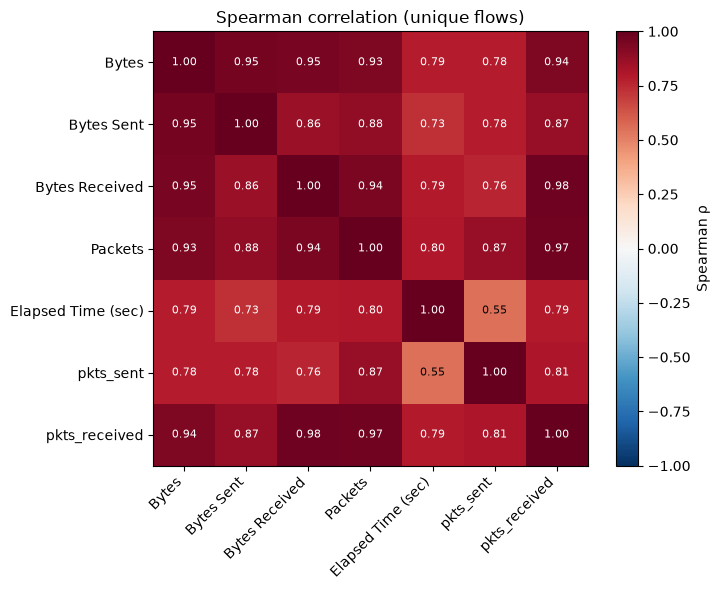

In [6]:
rho, pv = stats.spearmanr(df[NUMERIC])
pairs = [(NUMERIC[i], NUMERIC[j], rho[i, j], pv[i, j]) for i in range(len(NUMERIC)) for j in range(i + 1, len(NUMERIC))]
sp = pd.DataFrame(pairs, columns=["feature 1", "feature 2", "rho", "p"])
sp["p BH"] = bh(sp["p"]); sp = sp.sort_values("rho", key=abs, ascending=False)
display(sp.head(10).style.format({"rho": "{:+.3f}", "p": fmt, "p BH": fmt}))
sp.to_csv(REP / "spearman_correlations.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=45, ha="right"); ax.set_yticks(range(len(NUMERIC)), NUMERIC)
for i in range(len(NUMERIC)):
    for j in range(len(NUMERIC)):
        ax.text(j, i, f"{rho[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(rho[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Spearman ρ"); ax.set_title("Spearman correlation (unique flows)")
plt.tight_layout(); fig.savefig(FIG / "spearman_heatmap.png", dpi=200, bbox_inches="tight"); plt.show()
best = sp.iloc[0]
summary.append({"test": f"Spearman, {best['feature 1']} vs {best['feature 2']}", "statistic": round(best["rho"], 3),
                "p_value": best["p BH"], "effect_size": f"ρ = {best['rho']:+.3f}", "conclusion": "strong monotonic relation"})

## Summary table (copy into the report and README)

In [7]:
summary_df = pd.DataFrame(summary)
summary_df["p_value"] = summary_df["p_value"].map(lambda p: fmt(p) if isinstance(p, (float, np.floating)) else p)
summary_df.to_csv(REP / "statistical_tests_summary.csv", index=False)
display(summary_df)

,test,statistic,p_value,effect_size,conclusion
0,"Shapiro–Wilk on log1p(Bytes), each action",see table,2.0771e-06,-,normality rejected in all four groups
1,"Brown–Forsythe (Levene, median)",6216.6,< 1e-300 (numerical underflow),-,variances differ between actions
2,"Kruskal–Wallis, Bytes by action",34771.0,< 1e-300 (numerical underflow),ε² = 0.608,distributions differ
3,"Kruskal–Wallis, Elapsed Time (sec) by action",40093.0,< 1e-300 (numerical underflow),ε² = 0.701,distributions differ
4,"Dunn post-hoc (Holm), deny vs reset-both, Bytes",-5.15,5.1986e-07,δ = -0.504,see interpretation
5,"χ², NAT source-port status × action",55264.0,< 1e-300 (numerical underflow),V = 0.983,strong association
6,"χ², destination port (top 10) × action",88899.0,0.0010,V = 0.720,strong association
7,"Spearman, Bytes Received vs pkts_received",0.976,< 1e-300 (numerical underflow),ρ = +0.976,strong monotonic relation


## Conclusions (write them from your outputs)

1. **Test choice:** normality and equal variances are rejected (test 1), which *justifies* the non-parametric tests used everywhere else.
2. **Which features separate the actions:** rank them by ε² (test 2). These should match the most important features of the model (Elapsed Time, Destination Port).
3. **Which pairs differ:** from test 3, explain the `deny` vs `reset-both` result and link it to the confusion matrices of Notebook 05.
4. **Categorical associations:** from test 4, the destination port and NAT status are strongly associated with the action (Cramér's V), consistent with port-based firewall rules.
5. **Redundancy:** from test 5, the near-perfect correlations (e.g. Bytes with Bytes Sent/Received and Packets) explain why several features carry no extra permutation importance.